# Ejercicio series temporales

El archivo "Electric_Production.csv" contiene datos de la evolución de la producción eléctrica desde el año 1985. Se pide, descomponer ([seasonal_decompose](https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.seasonal_decompose.html)) la serie temporal. Para ello, debereis decidir que tipo de descomposición requiere  y representar la descomposición para su visualización.
Responde a las siguientes preguntas:

- Comprueba si la serie temporal tiene componente estacional.
- ¿Qué tipo de descomposición has aplicado? ¿Por qué? 
- ¿Presenta tendencia la serie temporal? En caso afirmativo, ¿cómo es la tendencia?
- ¿Es estacional la serie temporal? En caso afirmatico ¿cuál es el periodo de la componente estacional?
- ¿Se detectan puntos de impacto? En caso afirmativo indica en que instante temporal se encuentran.
- ¿Es estrictamente estacionario el residuo de la serie? Para ello, tendréis que hacer uso de los test estadísticos de Augmented Dickey Fuller ([ADF](https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.adfuller.html)) y  Kwiatkowski-Phillips-Schmidt-Shin ([KPSS](https://www.statsmodels.org/dev/generated/statsmodels.tsa.stattools.kpss.html#statsmodels.tsa.stattools.kpss)) que permiten comprobar la estacionariedad en series temporales. También deberéis comprobar que es estacionario en varianza aplicando el [test de heterocedasticidad](https://www.statsmodels.org/dev/generated/statsmodels.stats.diagnostic.het_arch.html).
- En caso de presentar heterocedasticidad, modelar la variación de la varianza utilizamos [ARCH/GARCH](https://pypi.org/project/arch/). Recordad que una vez extraido correctamente el modelos de la varianza, el residuo restante debería ser estrictamente estacionario.

Para saber el número de puntos que tiene un cierto intervalo temporal, y poder así hacer una mejor definición del periodo de la componente estacional, se puede hacer uso de la librería [pandas.DaraFrame.resample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import kpss, adfuller
from statsmodels.graphics import tsaplots
from statsmodels.stats.diagnostic import het_arch
from arch import arch_model

In [2]:
data = pd.read_csv("Electric_Production.csv", header=0,parse_dates=[0], index_col=[0])
data.head()

,Value
DATE,
1985-01-01,72.5052
1985-02-01,70.6720
1985-03-01,62.4502
1985-04-01,57.4714
1985-05-01,55.3151


<Axes: xlabel='DATE'>

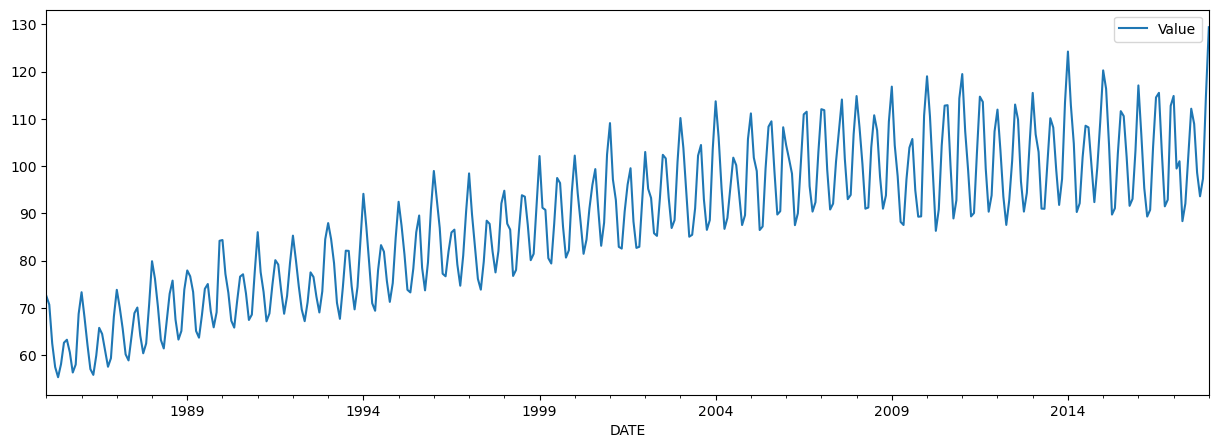

In [3]:
data.plot(figsize=(15,5))

## Estacionalidad

Frecuencia: MS
Rango: 1985-01-01 -> 2018-01-01 | n = 397
DATE
1985-01-01    12
1986-01-01    12
1987-01-01    12
1988-01-01    12
1989-01-01    12
Freq: YS-JAN, Name: Value, dtype: int64


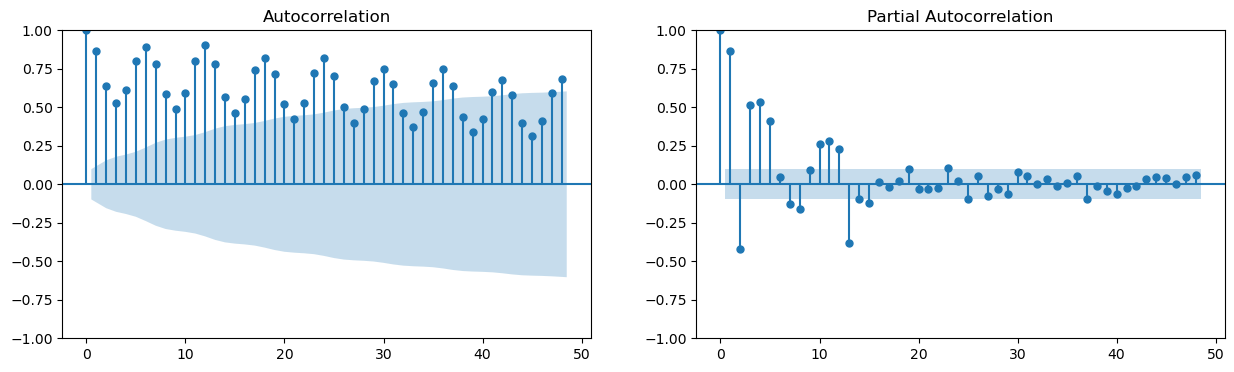

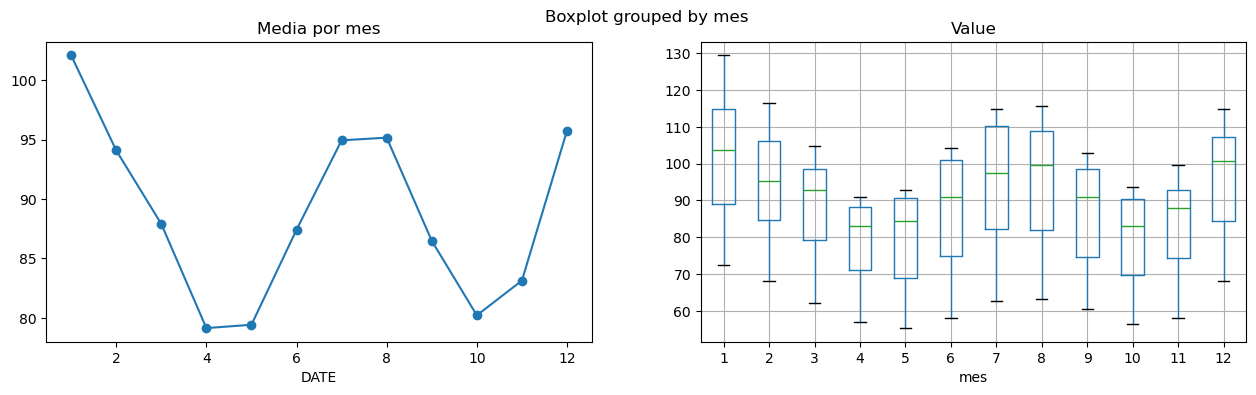

Periodos dominantes (meses): [6.0, 397.0, 12.0, 5.9, 6.1]


In [4]:
from scipy.signal import periodogram

serie = data["Value"]

print("Frecuencia:", pd.infer_freq(serie.index))   # MS = mensual
print("Rango:", serie.index.min().date(), "->", serie.index.max().date(), "| n =", len(serie))
print(serie.resample("YS").count().head())          # 12 puntos por año

# Autocorrelación: picos en 12, 24, 36... indican estacionalidad anual
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
tsaplots.plot_acf(serie, lags=48, ax=ax[0])
tsaplots.plot_pacf(serie, lags=48, ax=ax[1])
plt.show()

# Perfil medio por mes
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
serie.groupby(serie.index.month).mean().plot(marker="o", ax=ax[0], title="Media por mes")
serie.to_frame().assign(mes=serie.index.month).boxplot(column="Value", by="mes", ax=ax[1])
plt.show()

# Periodograma (quitando tendencia lineal)
f, pxx = periodogram(serie.values, detrend="linear")
top = np.argsort(pxx[1:])[::-1][:5] + 1
print("Periodos dominantes (meses):", [round(1 / f[i], 1) for i in top])

## Aditiva o multiplicativa

       media  rango    std
media  1.000  0.791  0.893
rango  0.791  1.000  0.934
std    0.893  0.934  1.000


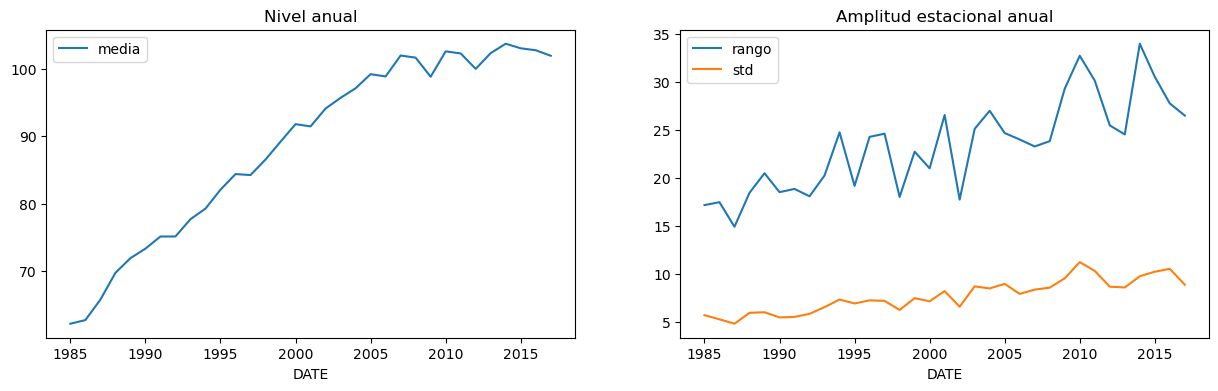

In [5]:
# Se excluye 2018 por estar incompleto (solo enero)
g = serie[serie.index.year < 2018].groupby(serie.index.year[serie.index.year < 2018])
estad = pd.DataFrame({"media": g.mean(), "rango": g.max() - g.min(), "std": g.std()})
print(estad.corr().round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
estad[["media"]].plot(ax=ax[0], title="Nivel anual")
estad[["rango", "std"]].plot(ax=ax[1], title="Amplitud estacional anual")
plt.show()

## Descomposicion

C:\Users\maren\AppData\Local\Temp\ipykernel_24748\3754461300.py:4: FutureWarning: `extrapolate_trend='freq'` is deprecated and will be removed in 0.16, use `extrapolate_trend='period'` instead.
  dec = seasonal_decompose(serie, model=modelo, period=12, extrapolate_trend="freq")


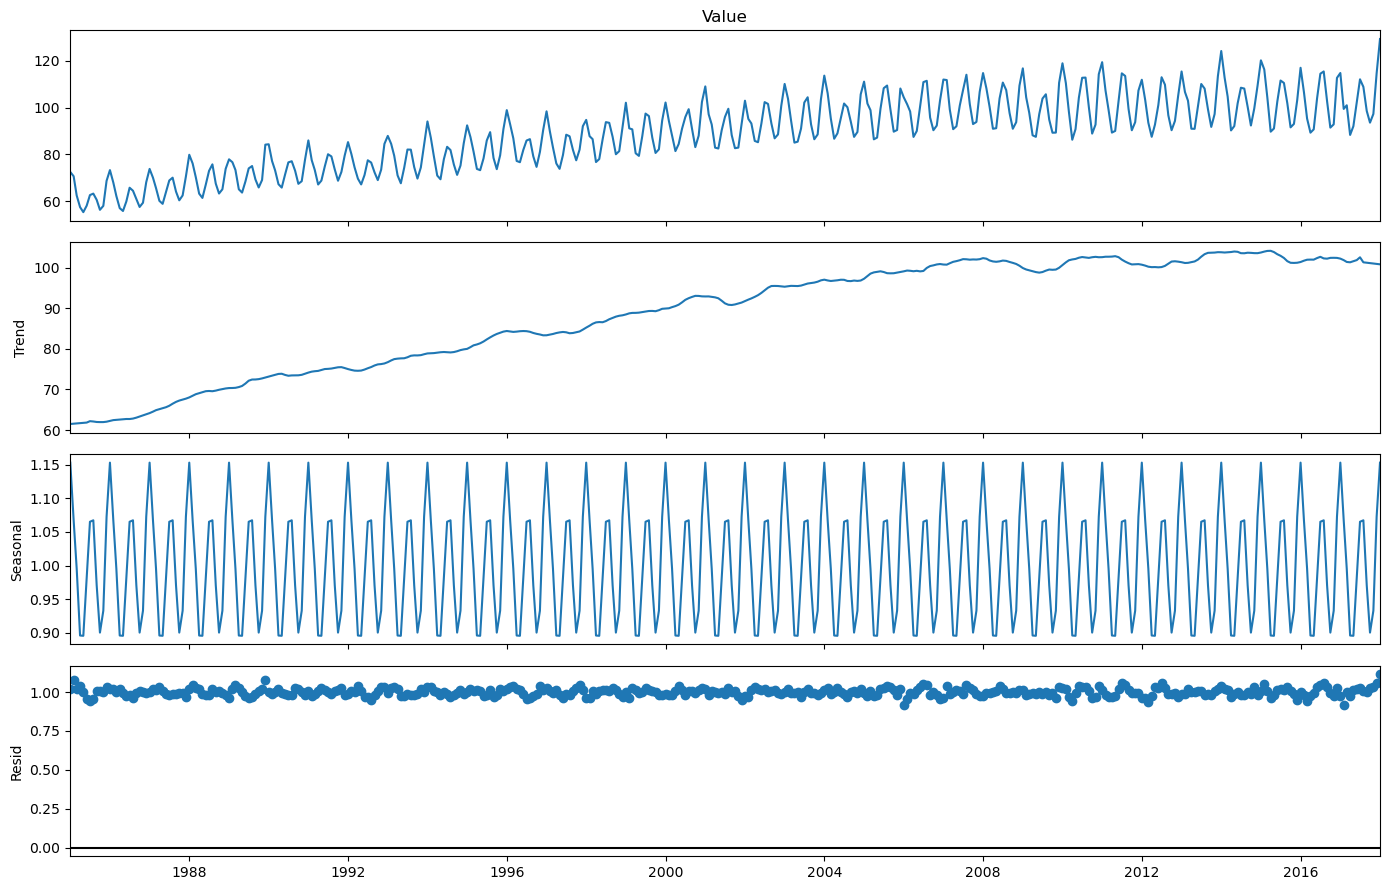

In [6]:
modelo = "multiplicative"   # cámbialo a "additive" si la celda 2 lo indica

# extrapolate_trend="freq" evita NaN en los extremos (así se analiza también el último dato)
dec = seasonal_decompose(serie, model=modelo, period=12, extrapolate_trend="freq")

fig = dec.plot()
fig.set_size_inches(14, 9)
plt.tight_layout()
plt.show()

## Tendencia y estacionalidad

In [7]:
from scipy import stats

trend = dec.trend
x = np.arange(len(trend))
pend, _, r, p, _ = stats.linregress(x, trend.values)
print(f"Pendiente global: {pend:.4f} por mes ({pend*12:.2f} por año), R2={r**2:.3f}")

# ¿La pendiente cambia con el tiempo?
for ini, fin in [("1985", "2007"), ("2008", "2018")]:
    t = trend.loc[ini:fin]
    s = stats.linregress(np.arange(len(t)), t.values)[0]
    print(f"Pendiente {ini}-{fin}: {s*12:.2f} por año")

print("Media anual:")
print(serie.groupby(serie.index.year).mean().round(1).to_string())

ciclo = dec.seasonal.iloc[:12]
print("\nComponente estacional (12 meses):")
print(ciclo.round(3).to_string())

resid = dec.resid
Fs = max(0, 1 - resid.var() / (dec.seasonal + resid).var())
Ft = max(0, 1 - resid.var() / (dec.trend + resid).var())
print(f"\nFuerza estacionalidad: {Fs:.3f} | Fuerza tendencia: {Ft:.3f}")

Pendiente global: 0.1108 por mes (1.33 por año), R2=0.923
Pendiente 1985-2007: 1.79 por año
Pendiente 2008-2018: 0.17 por año
Media anual:
DATE
1985     62.2
1986     62.7
1987     65.7
1988     69.7
1989     71.9
1990     73.3
1991     75.1
1992     75.1
1993     77.7
1994     79.3
1995     82.1
1996     84.4
1997     84.2
1998     86.5
1999     89.2
2000     91.8
2001     91.5
2002     94.1
2003     95.7
2004     97.1
2005     99.2
2006     98.9
2007    102.0
2008    101.7
2009     98.8
2010    102.6
2011    102.3
2012    100.0
2013    102.3
2014    103.7
2015    103.1
2016    102.8
2017    101.9
2018    129.4

Componente estacional (12 meses):
DATE
1985-01-01    1.153
1985-02-01    1.067
1985-03-01    0.996
1985-04-01    0.896
1985-05-01    0.896
1985-06-01    0.983
1985-07-01    1.065
1985-08-01    1.067
1985-09-01    0.971
1985-10-01    0.901
1985-11-01    0.933
1985-12-01    1.073

Fuerza estacionalidad: 0.914 | Fuerza tendencia: 1.000


## Puntos de impacto

Puntos de impacto (|z robusto| > 3): 4
            residuo      z
DATE                      
1989-12-01    1.076  3.027
2006-01-01    0.914 -3.510
2017-02-01    0.915 -3.481
2018-01-01    1.113  4.529


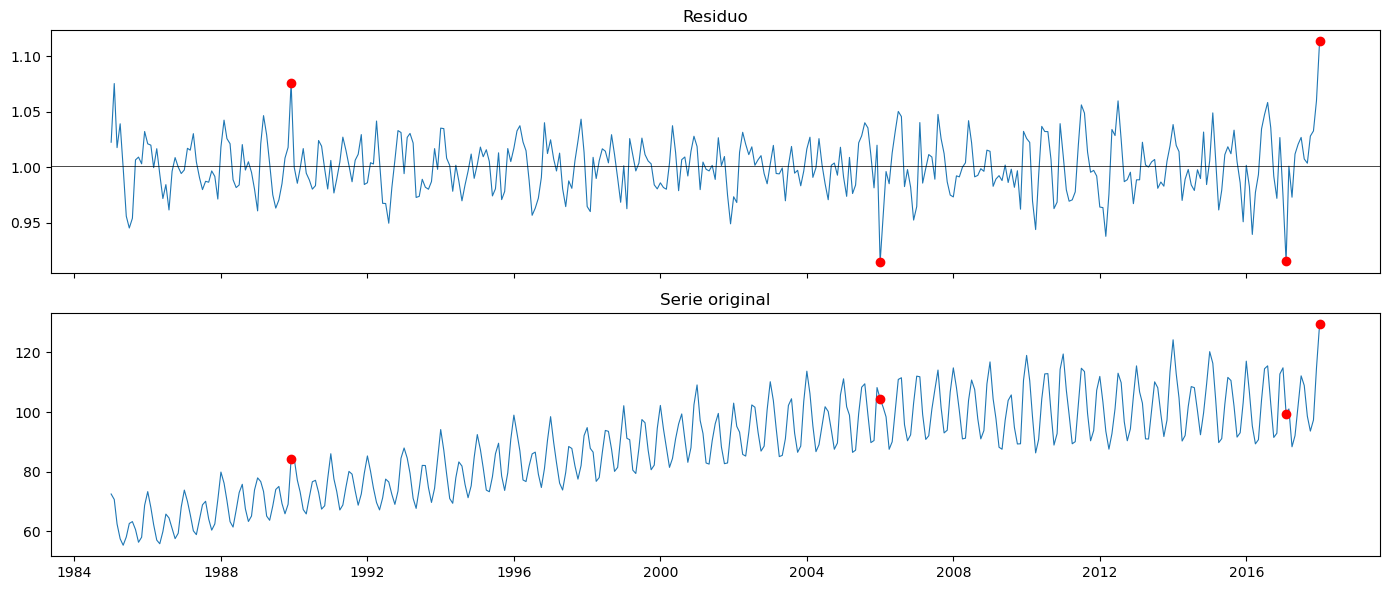

In [8]:
resid = dec.resid.dropna()
mad = np.median(np.abs(resid - resid.median())) * 1.4826
z = (resid - resid.median()) / mad
outliers = resid[z.abs() > 3]

print("Puntos de impacto (|z robusto| > 3):", len(outliers))
print(pd.DataFrame({"residuo": outliers, "z": z[outliers.index]}).round(3))

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
ax[0].plot(resid, lw=0.8)
ax[0].scatter(outliers.index, outliers.values, color="r", zorder=3)
ax[0].axhline(resid.median(), color="k", lw=0.5)
ax[0].set_title("Residuo")
ax[1].plot(serie, lw=0.8)
ax[1].scatter(outliers.index, serie.loc[outliers.index], color="r", zorder=3)
ax[1].set_title("Serie original")
plt.tight_layout()
plt.show()

## Estacionariedad

--- Residuo de la descomposición ---
ADF : estadístico=-9.277, p-valor=1.284e-15  (H0: raíz unitaria)
KPSS: estadístico=0.046, p-valor=0.1  (H0: estacionaria)
ARCH-LM: LM=137.532, p-valor=1.884e-23  (H0: homocedasticidad)
Estacionario en media: True
Estacionario en varianza (homocedástico): False


C:\Users\maren\AppData\Local\Temp\ipykernel_24748\1102711674.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, autolag="AIC")
C:\Users\maren\AppData\Local\Temp\ipykernel_24748\1102711674.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp_stat, kp_p, kp_lags, kp_crit = kpss(x, regression="c", nlags="auto")
C:\Users\maren\AppData\Local\Temp\ipykernel_24748\1102711674.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release

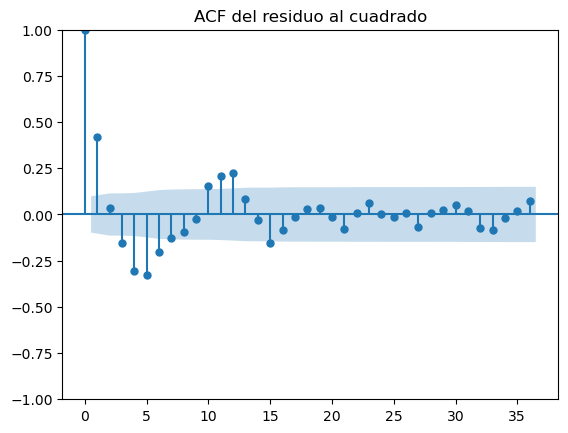

In [9]:
def tests_estacionariedad(x, nombre="Residuo"):
    x = pd.Series(x).dropna()

    adf = adfuller(x, autolag="AIC")
    kp_stat, kp_p, kp_lags, kp_crit = kpss(x, regression="c", nlags="auto")
    lm, lm_p, f, f_p = het_arch(x, nlags=12)

    print(f"--- {nombre} ---")
    print(f"ADF : estadístico={adf[0]:.3f}, p-valor={adf[1]:.4g}  (H0: raíz unitaria)")
    print(f"KPSS: estadístico={kp_stat:.3f}, p-valor={kp_p:.4g}  (H0: estacionaria)")
    print(f"ARCH-LM: LM={lm:.3f}, p-valor={lm_p:.4g}  (H0: homocedasticidad)")

    en_media = adf[1] < 0.05 and kp_p >= 0.05
    en_var = lm_p >= 0.05
    print("Estacionario en media:", en_media)
    print("Estacionario en varianza (homocedástico):", en_var)
    return en_media, en_var

resid = dec.resid.dropna()
tests_estacionariedad(resid, "Residuo de la descomposición")

tsaplots.plot_acf(resid ** 2, lags=36)   # si hay picos, hay efecto ARCH
plt.title("ACF del residuo al cuadrado")
plt.show()

## Modelar varianza con GARCH

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  resid   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -912.471
Distribution:                  Normal   AIC:                           1832.94
Method:            Maximum Likelihood   BIC:                           1848.88
                                        No. Observations:                  397
Date:               ju., oct. 15 2026   Df Residuals:                      396
Time:                        10:16:11   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.0173      0.112      0.155      0.877 [ -0.202,  0.23

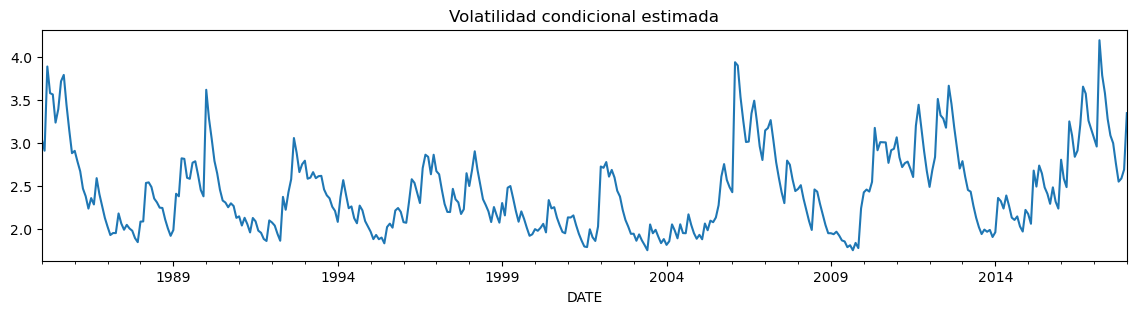

--- Residuo estandarizado (GARCH) ---
ADF : estadístico=-8.480, p-valor=1.403e-13  (H0: raíz unitaria)
KPSS: estadístico=0.022, p-valor=0.1  (H0: estacionaria)
ARCH-LM: LM=20.163, p-valor=0.06406  (H0: homocedasticidad)
Estacionario en media: True
Estacionario en varianza (homocedástico): True


C:\Users\maren\AppData\Local\Temp\ipykernel_24748\1102711674.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, autolag="AIC")
C:\Users\maren\AppData\Local\Temp\ipykernel_24748\1102711674.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kp_stat, kp_p, kp_lags, kp_crit = kpss(x, regression="c", nlags="auto")
C:\Users\maren\AppData\Local\Temp\ipykernel_24748\1102711674.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release

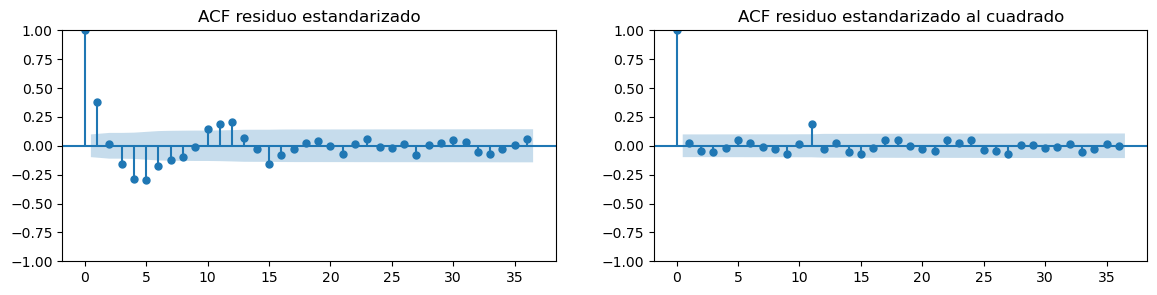

In [10]:
# arch_model prefiere series en escala "porcentual": si el residuo es multiplicativo (~1), se centra y escala
r = (resid - 1) * 100 if modelo == "multiplicative" else resid

am = arch_model(r, mean="Constant", vol="GARCH", p=1, q=1, dist="normal")
res = am.fit(disp="off")
print(res.summary())

res.conditional_volatility.plot(figsize=(14, 3), title="Volatilidad condicional estimada")
plt.show()

# Tras extraer el modelo de la varianza, el residuo estandarizado debería ser estacionario
std_resid = res.std_resid.dropna()
tests_estacionariedad(std_resid, "Residuo estandarizado (GARCH)")

fig, ax = plt.subplots(1, 2, figsize=(14, 3))
tsaplots.plot_acf(std_resid, lags=36, ax=ax[0], title="ACF residuo estandarizado")
tsaplots.plot_acf(std_resid ** 2, lags=36, ax=ax[1], title="ACF residuo estandarizado al cuadrado")
plt.show()